In [1]:

# Pokémon Card PreGrader
# Experiment setup

from pathlib import Path
import platform
import sys

print("Pokémon Card PreGrader — Experiment")
print("Python version:", sys.version.split()[0])
print("Operating system:", platform.system())

# Create a folder for our experiment files
experiment_dir = Path("pokemon_card_experiment")
experiment_dir.mkdir(exist_ok=True)

print("Experiment folder:", experiment_dir.resolve())
print("Setup successful!")


Pokémon Card PreGrader — Experiment
Python version: 3.13.16
Operating system: Linux
Experiment folder: /content/pokemon_card_experiment
Setup successful!


In [2]:

import pandas as pd
from pathlib import Path

# Define the experiment folder
experiment_dir = Path("pokemon_card_experiment")
experiment_dir.mkdir(exist_ok=True)

# Define the defects we want to investigate
defect_categories = [
    "centering",
    "corner_wear",
    "edge_wear",
    "surface_scratch"
]

# Create an empty reference dataset.
# We will fill this with observations from actual card photos.
reference = pd.DataFrame(columns=["image_id", "defect"])

# Create an empty predictions dataset.
# We will fill this with actual model outputs later.
predictions = pd.DataFrame(
    columns=["model", "image_id", "defect", "detected"]
)

reference.to_csv(experiment_dir / "reference_defects.csv", index=False)
predictions.to_csv(experiment_dir / "predictions.csv", index=False)

print("Defect categories:", defect_categories)
print("Reference dataset created:", len(reference), "rows")
print("Predictions dataset created:", len(predictions), "rows")
print("Files saved in:", experiment_dir.resolve())


Defect categories: ['centering', 'corner_wear', 'edge_wear', 'surface_scratch']
Reference dataset created: 0 rows
Predictions dataset created: 0 rows
Files saved in: /content/pokemon_card_experiment


In [3]:

for file in sorted(experiment_dir.glob("*.csv")):
    print(file.name)
    print(pd.read_csv(file).head())
    print()


predictions.csv
Empty DataFrame
Columns: [model, image_id, defect, detected]
Index: []

reference_defects.csv
Empty DataFrame
Columns: [image_id, defect]
Index: []



In [4]:

import pandas as pd
from pathlib import Path

experiment_dir = Path("pokemon_card_experiment")

# Example reference labels — replace these with observations
# from your own Pokémon card photos.
reference = pd.DataFrame([
    {
        "image_id": "card_01",
        "defect": "corner_wear",
        "notes": "Example only — replace with your actual observation"
    }
])

reference.to_csv(
    experiment_dir / "reference_defects.csv",
    index=False
)

print(reference)
print("\nReference labels saved successfully.")


  image_id       defect                                              notes
0  card_01  corner_wear  Example only — replace with your actual observ...

Reference labels saved successfully.


In [5]:

import pandas as pd
from pathlib import Path

experiment_dir = Path("pokemon_card_experiment")

image_id = input("Enter a short ID for your card (e.g. card_01): ")
defect = input(
    "Enter the visible defect "
    "(centering, corner_wear, edge_wear, surface_scratch): "
)
notes = input("Describe what you can actually see: ")

reference = pd.read_csv(
    experiment_dir / "reference_defects.csv"
)

# Replace the example row with your actual observation.
reference = reference[reference["image_id"] != image_id]

reference = pd.concat([
    reference,
    pd.DataFrame([{
        "image_id": image_id,
        "defect": defect,
        "notes": notes
    }])
], ignore_index=True)

reference.to_csv(
    experiment_dir / "reference_defects.csv",
    index=False
)

print("\nSaved reference label:")
print(reference.tail(1).to_string(index=False))


Enter a short ID for your card (e.g. card_01): card_01
Enter the visible defect (centering, corner_wear, edge_wear, surface_scratch): surface_scratch
Describe what you can actually see: The surface is severely scratched, and the corners are worn as well

Saved reference label:
image_id          defect                                                               notes
 card_01 surface_scratch The surface is severely scratched, and the corners are worn as well


In [6]:

import pandas as pd
from pathlib import Path

experiment_dir = Path("pokemon_card_experiment")
file_path = experiment_dir / "reference_defects.csv"

reference = pd.read_csv(file_path)

# Add corner wear as a second defect on the same card.
new_label = pd.DataFrame([{
    "image_id": "card_01",
    "defect": "corner_wear",
    "notes": "The corners are worn, based on my visual inspection."
}])

reference = pd.concat(
    [reference, new_label],
    ignore_index=True
)

reference.to_csv(file_path, index=False)

print(reference.to_string(index=False))
print("\nTotal defect labels:", len(reference))


image_id          defect                                                               notes
 card_01 surface_scratch The surface is severely scratched, and the corners are worn as well
 card_01     corner_wear                The corners are worn, based on my visual inspection.

Total defect labels: 2


In [7]:

import pandas as pd
from pathlib import Path

file_path = Path("pokemon_card_experiment/reference_defects.csv")
reference = pd.read_csv(file_path)

print("REFERENCE DATASET")
print("=================")
print(reference.to_string(index=False))

print("\nUnique cards:", reference["image_id"].nunique())
print("Total defect labels:", len(reference))
print("Defect categories:", sorted(reference["defect"].unique()))


REFERENCE DATASET
image_id          defect                                                               notes
 card_01 surface_scratch The surface is severely scratched, and the corners are worn as well
 card_01     corner_wear                The corners are worn, based on my visual inspection.

Unique cards: 1
Total defect labels: 2
Defect categories: ['corner_wear', 'surface_scratch']


In [8]:

from google.colab import files
from pathlib import Path

uploaded = files.upload()

experiment_dir = Path("pokemon_card_experiment")
experiment_dir.mkdir(exist_ok=True)

for filename, content in uploaded.items():
    destination = experiment_dir / "card_01.jpg"
    destination.write_bytes(content)
    print("Photo saved to:", destination)
    print("File size:", len(content), "bytes")


Saving puaf47soyl8e1.jpg to puaf47soyl8e1.jpg
Photo saved to: pokemon_card_experiment/card_01.jpg
File size: 731274 bytes


Image format: JPEG
Image dimensions: (2160, 3840)


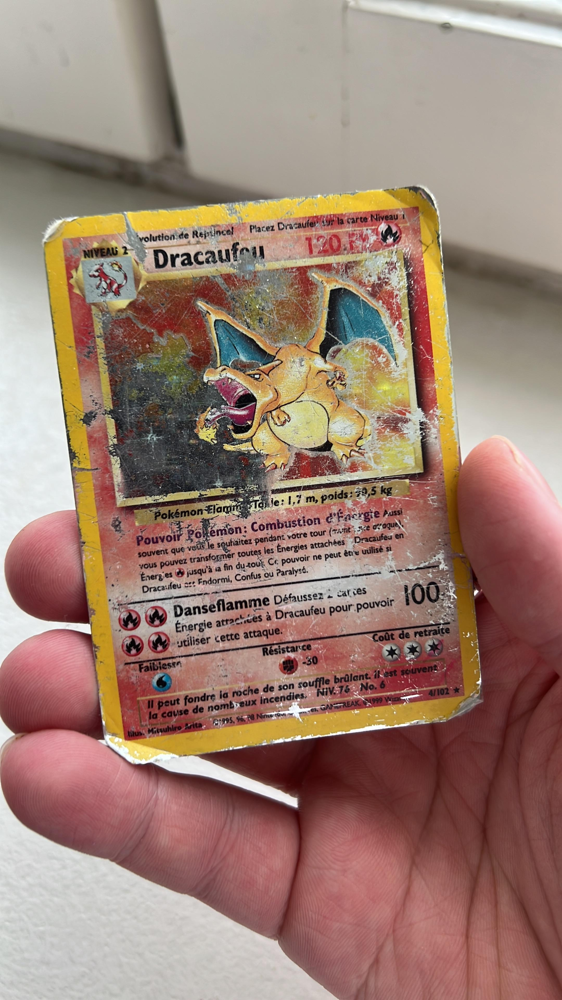

In [9]:

from PIL import Image
from IPython.display import display
from pathlib import Path

image_path = Path("pokemon_card_experiment/card_01.jpg")

card_image = Image.open(image_path)

print("Image format:", card_image.format)
print("Image dimensions:", card_image.size)
display(card_image)


In [10]:

prompt = """
You are assisting with a preliminary visual inspection of a Pokémon card.

Inspect the provided photograph for these visible defect categories:
1. centering: visibly uneven borders or off-center artwork
2. corner_wear: whitening, rounding, or damage at corners
3. edge_wear: whitening, chipping, or damage along edges
4. surface_scratch: visible scratches or marks on the surface

For each category, return:
- detected: yes, no, or uncertain
- evidence: a short description of what is visible
- confidence: low, medium, or high

Do not invent details that cannot be seen in the photograph.
Do not claim to provide an official professional grade.
Mention image-quality limitations if relevant.
"""

print(prompt)



You are assisting with a preliminary visual inspection of a Pokémon card.

Inspect the provided photograph for these visible defect categories:
1. centering: visibly uneven borders or off-center artwork
2. corner_wear: whitening, rounding, or damage at corners
3. edge_wear: whitening, chipping, or damage along edges
4. surface_scratch: visible scratches or marks on the surface

For each category, return:
- detected: yes, no, or uncertain
- evidence: a short description of what is visible
- confidence: low, medium, or high

Do not invent details that cannot be seen in the photograph.
Do not claim to provide an official professional grade.
Mention image-quality limitations if relevant.



In [11]:

import pandas as pd
from pathlib import Path

experiment_dir = Path("pokemon_card_experiment")
reference = pd.read_csv(
    experiment_dir / "reference_defects.csv"
)

# Predictions reported by the AI for our actual photo.
ai_predictions = pd.DataFrame([
    {
        "model": "ChatGPT vision",
        "image_id": "card_01",
        "defect": "centering",
        "detected": "yes"
    },
    {
        "model": "ChatGPT vision",
        "image_id": "card_01",
        "defect": "corner_wear",
        "detected": "yes"
    },
    {
        "model": "ChatGPT vision",
        "image_id": "card_01",
        "defect": "edge_wear",
        "detected": "yes"
    },
    {
        "model": "ChatGPT vision",
        "image_id": "card_01",
        "defect": "surface_scratch",
        "detected": "yes"
    }
])

ai_predictions.to_csv(
    experiment_dir / "predictions.csv",
    index=False
)

print("AI PREDICTIONS")
print(ai_predictions.to_string(index=False))

print("\nREFERENCE LABELS")
print(reference[["image_id", "defect"]].to_string(index=False))
print("\nPredictions saved successfully.")


AI PREDICTIONS
         model image_id          defect detected
ChatGPT vision  card_01       centering      yes
ChatGPT vision  card_01     corner_wear      yes
ChatGPT vision  card_01       edge_wear      yes
ChatGPT vision  card_01 surface_scratch      yes

REFERENCE LABELS
image_id          defect
 card_01 surface_scratch
 card_01     corner_wear

Predictions saved successfully.


In [12]:

import pandas as pd
from pathlib import Path

experiment_dir = Path("pokemon_card_experiment")

reference = pd.read_csv(
    experiment_dir / "reference_defects.csv"
)
predictions = pd.read_csv(
    experiment_dir / "predictions.csv"
)

# Compare only defects recorded in the reference labels.
comparison = reference.merge(
    predictions[["image_id", "defect", "detected"]],
    on=["image_id", "defect"],
    how="left"
)

comparison["correct_detection"] = (
    comparison["detected"].str.lower() == "yes"
)

total_reference_defects = len(comparison)
correctly_detected = int(
    comparison["correct_detection"].sum()
)

recall = (
    correctly_detected / total_reference_defects * 100
    if total_reference_defects > 0 else 0
)

print("REFERENCE DEFECT COMPARISON")
print(comparison.to_string(index=False))
print(f"\nReference defects: {total_reference_defects}")
print(f"Detected by AI: {correctly_detected}")
print(f"Defect recall: {recall:.1f}%")
print("\nImportant: This is a one-card pilot, not a reliable")
print("estimate of overall model performance.")


REFERENCE DEFECT COMPARISON
image_id          defect                                                               notes detected  correct_detection
 card_01 surface_scratch The surface is severely scratched, and the corners are worn as well      yes               True
 card_01     corner_wear                The corners are worn, based on my visual inspection.      yes               True

Reference defects: 2
Detected by AI: 2
Defect recall: 100.0%

Important: This is a one-card pilot, not a reliable
estimate of overall model performance.


In [13]:

from pathlib import Path

experiment_dir = Path("pokemon_card_experiment")

report = """# Pokémon Card PreGrader — Initial Experiment

## Objective
Test whether a vision-capable AI can identify visible Pokémon card defects.

## Method
- One actual Pokémon card photograph was inspected.
- A standardized prompt asked about centering, corner wear,
  edge wear, and surface scratches.
- Two reference defects were manually recorded:
  surface scratches and corner wear.
- The AI's written assessment was recorded in predictions.csv.

## Result
- Cards tested: 1
- Reference defect labels: 2
- Reference defects detected by AI: 2
- Preliminary defect recall: 100% (2/2)

## Interpretation
The AI reported both defects in the manual reference labels.
It also reported centering and edge wear, which have not yet
been independently verified against reference labels.

This is a one-card pilot and does not establish overall model
accuracy, grading reliability, or financial usefulness.

## Limitations
1. Only one card has been tested.
2. Reference labels are based on one person's visual inspection.
3. The AI response came from a chat interface, not a controlled
   API benchmark.
4. Photograph angle and reflections may affect observations.
5. No official professional grade was established.

## Next steps
Test more cards, use consistent photographs, and independently
verify reference labels before drawing conclusions.
"""

report_path = experiment_dir / "experiment_report.md"
report_path.write_text(report, encoding="utf-8")

print("Report saved to:", report_path)
print("\n", report)


Report saved to: pokemon_card_experiment/experiment_report.md

 # Pokémon Card PreGrader — Initial Experiment

## Objective
Test whether a vision-capable AI can identify visible Pokémon card defects.

## Method
- One actual Pokémon card photograph was inspected.
- A standardized prompt asked about centering, corner wear,
  edge wear, and surface scratches.
- Two reference defects were manually recorded:
  surface scratches and corner wear.
- The AI's written assessment was recorded in predictions.csv.

## Result
- Cards tested: 1
- Reference defect labels: 2
- Reference defects detected by AI: 2
- Preliminary defect recall: 100% (2/2)

## Interpretation
The AI reported both defects in the manual reference labels.
It also reported centering and edge wear, which have not yet
been independently verified against reference labels.

This is a one-card pilot and does not establish overall model
accuracy, grading reliability, or financial usefulness.

## Limitations
1. Only one card has been t

In [14]:

from google.colab import files
from pathlib import Path

report_path = Path(
    "pokemon_card_experiment/experiment_report.md"
)

files.download(str(report_path))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:

from google.colab import files
from pathlib import Path

experiment_dir = Path("pokemon_card_experiment")

files.download(str(experiment_dir / "reference_defects.csv"))
files.download(str(experiment_dir / "predictions.csv"))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>